In [10]:
%pip install pandas pyarrow matplotlib

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [11]:
from pathlib import Path
import hashlib
import urllib.request
import pandas as pd
import matplotlib.pyplot as plt

data_dir = Path("data")
data_dir.mkdir(exist_ok=True)

path = data_dir / "yellow_tripdata_2024-01.parquet"
url = (
    "https://d37ci6vzurychx.cloudfront.net/trip-data/"
    "yellow_tripdata_2024-01.parquet"
)

if not path.exists():
    urllib.request.urlretrieve(url, path)

expected_hash = (
    "c4d59da7bbc8abaeeeb1727947ee93d9891"
    "a71acb42854bd80db1571b2030510"
)
actual_hash = hashlib.sha256(path.read_bytes()).hexdigest()

assert actual_hash == expected_hash, "File differs from the documented snapshot."
print("January file downloaded and verified.")

January file downloaded and verified.


In [12]:
columns = [
    "tpep_pickup_datetime",
    "tpep_dropoff_datetime",
    "PULocationID",
    "DOLocationID",
]

raw = pd.read_parquet(path, columns=columns)

trips = raw.loc[
    raw["PULocationID"].isin([161, 162, 163, 230])
    & raw["DOLocationID"].eq(132)
    & raw["tpep_pickup_datetime"].ge(pd.Timestamp("2024-01-01"))
    & raw["tpep_pickup_datetime"].lt(pd.Timestamp("2024-02-01"))
].copy()

trips["duration_minutes"] = (
    trips["tpep_dropoff_datetime"]
    - trips["tpep_pickup_datetime"]
).dt.total_seconds() / 60

# These are investigation flags—not automatic deletion rules.
trips["missing_duration"] = trips["duration_minutes"].isna()
trips["nonpositive_duration"] = trips["duration_minutes"].le(0)
trips["over_six_hours"] = trips["duration_minutes"].gt(360)
trips["duplicate_candidate"] = trips.duplicated(
    subset=columns, keep=False
)

display(trips[
    ["missing_duration", "nonpositive_duration",
     "over_six_hours", "duplicate_candidate"]
].sum().to_frame("Flagged rows"))

display(trips.loc[
    trips["over_six_hours"] | trips["duplicate_candidate"]
].head(20))

,Flagged rows
missing_duration,0
nonpositive_duration,0
over_six_hours,13
duplicate_candidate,110


,tpep_pickup_datetime,tpep_dropoff_datetime,PULocationID,DOLocationID,duration_minutes,missing_duration,nonpositive_duration,over_six_hours,duplicate_candidate
33839,2024-01-01 12:23:34,2024-01-01 12:56:03,161,132,32.483333,False,False,False,True
33840,2024-01-01 12:23:34,2024-01-01 12:56:03,161,132,32.483333,False,False,False,True
49372,2024-01-01 16:50:17,2024-01-01 17:27:11,161,132,36.900000,False,False,False,True
49373,2024-01-01 16:50:17,2024-01-01 17:27:11,161,132,36.900000,False,False,False,True
55489,2024-01-01 18:04:29,2024-01-02 17:35:05,230,132,1410.600000,False,False,True,False
91331,2024-01-02 11:56:56,2024-01-02 12:50:45,230,132,53.816667,False,False,False,True
91332,2024-01-02 11:56:56,2024-01-02 12:50:45,230,132,53.816667,False,False,False,True
118292,2024-01-02 17:35:05,2024-01-02 18:46:50,163,132,71.750000,False,False,False,True
118293,2024-01-02 17:35:05,2024-01-02 18:46:50,163,132,71.750000,False,False,False,True
122258,2024-01-02 17:08:45,2024-01-02 18:01:24,161,132,52.650000,False,False,False,True


,January trip duration (minutes)
count,6885.000000
mean,52.674561
std,50.805019
min,5.150000
50%,49.983333
90%,71.183333
95%,76.696667
99%,90.285333
max,1436.100000


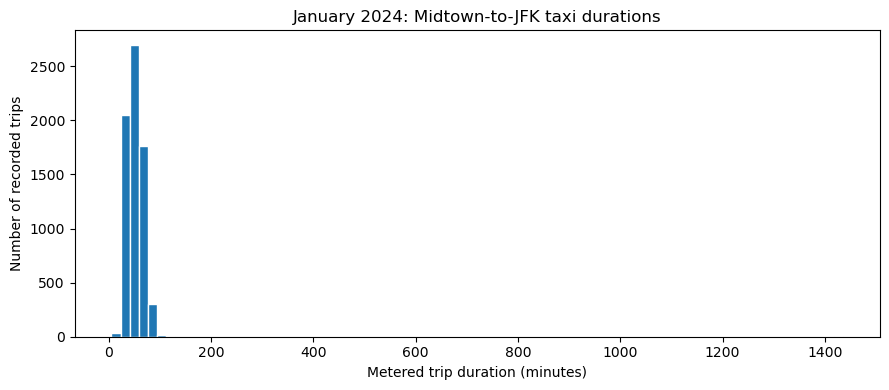

In [13]:
# Summarize positive trip durations.
# Keep long trips and possible duplicates for now.
positive = trips.loc[trips["duration_minutes"] > 0].copy()

display(
    positive["duration_minutes"]
    .describe(percentiles=[0.50, 0.90, 0.95, 0.99])
    .to_frame("January trip duration (minutes)")
)

# Plot all positive durations, including unusually long trips.
fig, ax = plt.subplots(figsize=(9, 4))

ax.hist(
    positive["duration_minutes"],
    bins=80,
    edgecolor="white"
)

ax.set_title("January 2024: Midtown-to-JFK taxi durations")
ax.set_xlabel("Metered trip duration (minutes)")
ax.set_ylabel("Number of recorded trips")

fig.tight_layout()

# Save the chart in the project's fig folder.
Path("fig").mkdir(exist_ok=True)
fig.savefig("fig/january_duration_histogram.png", dpi=150)

plt.show()

### January data check

The January sample contains 6,885 recorded Midtown-to-JFK trips.
The median metered duration is 49.98 minutes, and the empirical
90th percentile is 71.18 minutes. This is an initial fixed-allowance
benchmark before February calibration, not a tested recommendation.

There are no missing or nonpositive durations among these selected
records. However, 13 records exceed six hours, and 110 rows belong
to possible duplicate groups based on pickup/drop-off timestamps
and zones. These records remain included pending investigation.

The histogram shows most trips concentrated at shorter durations
with a long right tail. Metered duration excludes taxi waiting time
and airport processing, so these results describe the road portion
of the journey only.